# Predicting used-car prices in Sri Lanka with ensemble learning

**Problem (local):** buyers and sellers in Sri Lanka have no reliable way to judge a fair price for a used car.
Vehicle imports were suspended from 2020 and reopened only in 2025, so prices moved sharply and people mostly
guess from ikman.lk adverts. **Goal:** predict a fair asking price (in LKR lakhs, 1 lakh = Rs. 100,000) from a
car's listing details, and explain *why* the model gives that price.

**Type:** regression · **Data:** 11,750 real Sri Lankan listings (ikman.lk + Kaggle Sri Lanka car data)

| Assignment requirement | Section |
|---|---|
| Local problem and local dataset | 1, 2 |
| Exploratory data analysis | 3 |
| Preprocessing (null detection, imputation, transformation, encoding, scaling) | 4 |
| Suitable algorithms: bagging, boosting, stacking, voting; new models not used in class (CatBoost, LightGBM) | 5 |
| Hyperparameter tuning (no default parameters) | 6 |
| Evaluation, comparison and justification | 7, 8 |
| SHAP, LIME and interpretation | 9, 10 |
| Single-car inference, saved model (pickle) | 11 |
| Working application | 12 (`app.py`) |

In [1]:
import pickle, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score, mean_absolute_percentage_error, mean_squared_error
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from car_utils import FEATURES, NUM_FEATURES, CAT_FEATURES, fit_fill_stats, fill_missing

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

## 2. The dataset

In [2]:
raw = pd.read_csv("cars.csv")
print(raw.shape)
display(raw.head())
print("Explicit missing values per column:\n", raw.isna().sum().to_string())

(11750, 10)


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Condition,Price,Date
0,AUDI,A1,2016,990.0,AUTOMATIC,PETROL,99000.0,USED,100.0,2025-02-05
1,AUDI,A1,2016,1000.0,AUTOMATIC,PETROL,139000.0,USED,76.0,2026-09-26
2,AUDI,A1,2016,1000.0,AUTOMATIC,PETROL,105000.0,USED,80.0,2026-09-26
3,AUDI,A1,2017,1000.0,AUTOMATIC,PETROL,88000.0,USED,97.0,2025-01-14
4,AUDI,A1,2017,1000.0,AUTOMATIC,PETROL,88000.0,USED,107.0,2024-12-21


Explicit missing values per column:
 Brand          0
Model          0
YOM            0
Engine (cc)    0
Gear           0
Fuel Type      0
Millage(KM)    0
Condition      0
Price          0
Date           0


The data has **no explicit missing values**. The next section shows that missing values are hidden inside it.

## 3. Exploratory data analysis

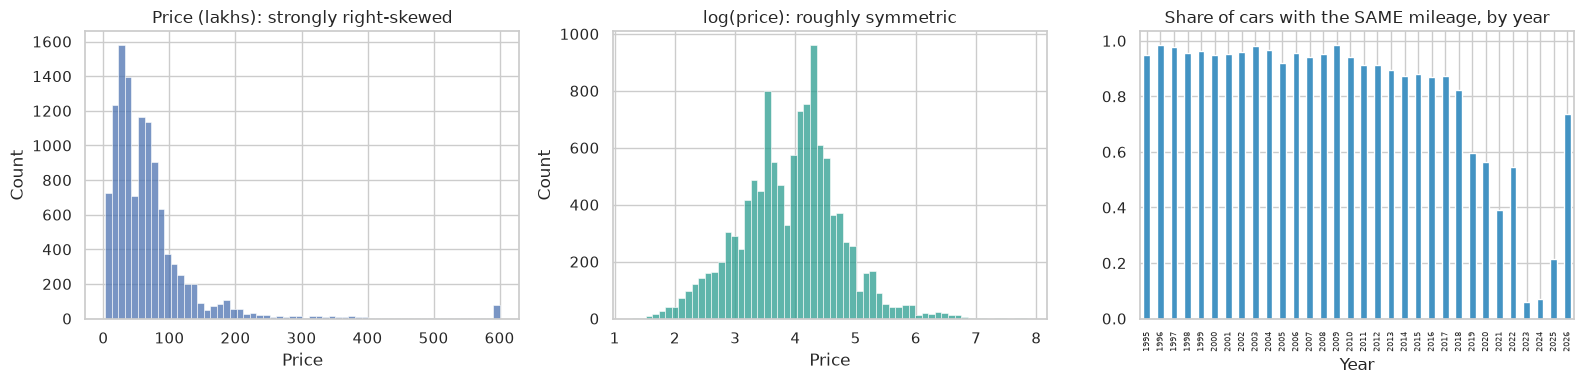

Price skewness: 8.9  | log-price skewness: 0.11
Duplicate rows: 1391
Most repeated prices:
 Price
28.5    57
65.0    56
75.0    55
32.5    55
26.5    53


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(raw["Price"].clip(upper=600), bins=60, ax=ax[0]); ax[0].set(title="Price (lakhs): strongly right-skewed")
sns.histplot(np.log1p(raw["Price"]), bins=60, ax=ax[1], color="#2a9d8f"); ax[1].set(title="log(price): roughly symmetric")
r = raw[raw.YOM >= 1995]
share = r.groupby("YOM")["Millage(KM)"].agg(lambda s: (s == s.mode().iloc[0]).mean())
share.plot.bar(ax=ax[2], color="#4393c3"); ax[2].set(title="Share of cars with the SAME mileage, by year", xlabel="Year")
ax[2].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.show()
print("Price skewness:", raw["Price"].skew().round(2), " | log-price skewness:", np.log1p(raw["Price"]).skew().round(2))
print("Duplicate rows:", raw.drop(columns="Date").duplicated().sum())
print("Most repeated prices:\n", raw["Price"].value_counts().head(5).to_string())

**What the EDA shows**
* **Price is very skewed** (skewness above 5), so the model predicts **log(price)**. This turns errors into
  percentages, which suits a market where cars range from Rs. 5 L to Rs. 1,500 L.
* **Hidden missing values in mileage.** For most years, 80–98% of cars have *exactly the same* mileage
  (for example, every 2014 Aqua shows 121,000 km). The source clearly filled in missing mileage per year.
* **Hidden missing values in price.** Values such as 71.356097 appear dozens of times across unrelated cars.
  These are averages the source filled in, not real asking prices.
* **Duplicates.** About 1,400 adverts are exact re-posts.

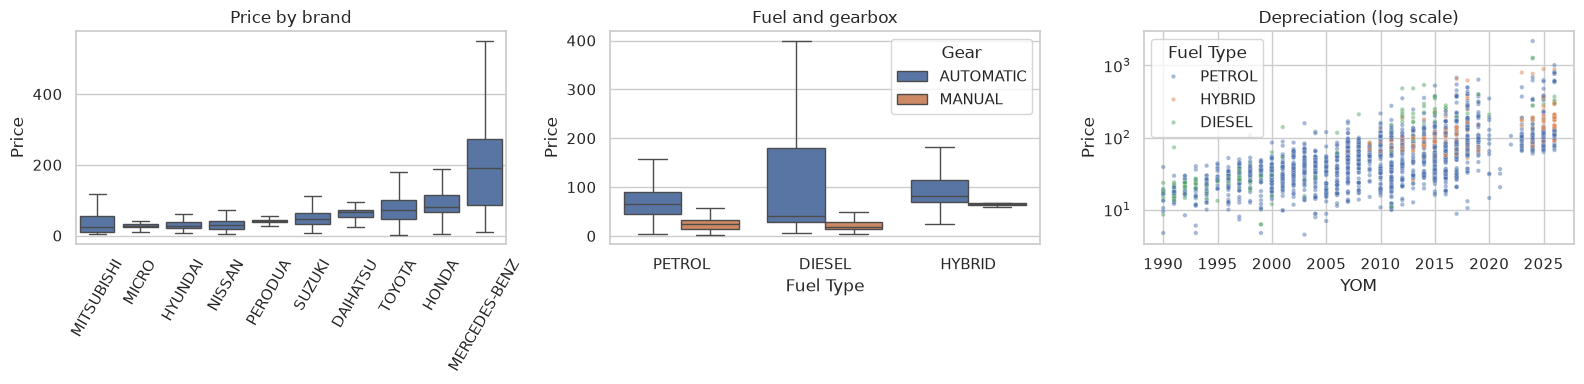

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
top = raw["Brand"].value_counts().head(10).index
order = raw[raw.Brand.isin(top)].groupby("Brand")["Price"].median().sort_values().index
sns.boxplot(data=raw[raw.Brand.isin(top)], x="Brand", y="Price", order=order, showfliers=False, ax=ax[0])
ax[0].tick_params(axis="x", rotation=60); ax[0].set(title="Price by brand", xlabel="")
sns.boxplot(data=raw, x="Fuel Type", y="Price", hue="Gear", showfliers=False, ax=ax[1]); ax[1].set(title="Fuel and gearbox")
sns.scatterplot(data=raw[raw.YOM >= 1990].sample(3000, random_state=0), x="YOM", y="Price", hue="Fuel Type",
                s=10, alpha=.5, ax=ax[2]); ax[2].set_yscale("log"); ax[2].set(title="Depreciation (log scale)")
plt.tight_layout(); plt.show()

* **Brand matters a lot.** Japanese and European brands keep their value, and Indian and Chinese budget brands are cheapest.
* **Automatics and hybrids cost more.** This reflects Sri Lankan fuel prices and the popularity of reconditioned Japanese hybrids.
* **Price falls steadily with age** (a straight line on the log scale), with different levels per brand and fuel.
  These are **non-linear interactions**, which tree ensembles learn well and a single linear model cannot.

## 4. Preprocessing
| Step | What and why |
|---|---|
| Rename columns | short, consistent names |
| Remove duplicates | re-posted adverts would leak between train and test |
| Remove filled-in prices | repeated many-decimal values are averages, not real prices |
| Scope | cars made from 1990 onwards; prices between 3 and 1,500 lakhs (removes errors and a few supercars) |
| **Null detection** | engine < 600 cc → missing; mileage equal to its year's filled-in value → missing |
| New features | `age` = listing year − year of manufacture; `mileage_reported` = 0/1; model name → first word |
| Rare categories | brands with < 20 cars and models with < 15 → "OTHER" |

In [5]:
df = raw.rename(columns={"Brand": "brand", "Model": "model_full", "Engine (cc)": "engine_cc", "Gear": "gear",
                         "Fuel Type": "fuel", "Millage(KM)": "mileage_km", "Condition": "condition",
                         "Price": "price", "Date": "date"})
df["date"] = pd.to_datetime(df["date"])
n0 = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "date"])
filled_price = ((df["price"] * 100 % 1).abs() > 1e-6) & (df.groupby("price")["price"].transform("size") >= 3)
df = df[~filled_price]
df = df[(df["YOM"] >= 1990) & df["price"].between(3, 1500)].copy()

# --- null detection ---
df.loc[df["engine_cc"] < 600, "engine_cc"] = np.nan
mode = df.groupby("YOM")["mileage_km"].transform(lambda s: s.mode().iloc[0])
share = df.groupby("YOM")["mileage_km"].transform(lambda s: (s == s.mode().iloc[0]).mean())
fake = (df["mileage_km"] == mode) & (share >= 0.30) & (df["condition"] == "USED")
df["mileage_reported"] = (~fake).astype(int)
df.loc[fake, "mileage_km"] = np.nan

# --- features ---
df["age"] = (df["date"].dt.year - df["YOM"]).clip(lower=0)
df["model"] = df["model_full"].str.split().str[0]
for col, k in [("brand", 20), ("model", 15)]:
    counts = df[col].value_counts()
    df[col] = df[col].where(df[col].map(counts) >= k, "OTHER")
df = df.reset_index(drop=True)
print(f"{n0:,} rows -> {len(df):,} after cleaning")
print("Missing values now visible:\n", df[FEATURES].isna().sum()[lambda s: s > 0].to_string())

11,750 rows -> 9,139 after cleaning
Missing values now visible:
 engine_cc        4
mileage_km    7025


**Hold one car out completely** (never used for training or testing) so we can demonstrate inference on a
genuinely new car at the end. Then make an 80/20 train/test split, stratified on price so cheap and expensive
cars appear in both.

In [6]:
hold_idx = df[(df.model_full == "AQUA") & (df.YOM == 2014) & (df.fuel == "HYBRID") & (df.price == 79.5)].index[0]
holdout = df.loc[[hold_idx]]
df = df.drop(index=hold_idx)

train, test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=pd.qcut(df["price"], 10, labels=False))

# Imputation statistics are learned from the TRAINING set only (no leakage into the test set)
stats = fit_fill_stats(train)
X_train, X_test = fill_missing(train, stats), fill_missing(test, stats)
y_train, y_test = np.log1p(train["price"].values), test["price"].values   # train on log(price)
print(f"Train {len(X_train):,} · Test {len(X_test):,} · typical km per year {stats['km_per_year']:,.0f}")
display(X_train.head())

Train 7,310 · Test 1,828 · typical km per year 8,523


,age,engine_cc,mileage_km,mileage_reported,brand,model,gear,fuel,condition
3499,23.0,1500.0,196022.727273,0.0,NISSAN,PULSAR,AUTOMATIC,PETROL,USED
3744,9.0,1000.0,76704.545455,0.0,PERODUA,AXIA,AUTOMATIC,PETROL,USED
232,23.0,1980.0,196022.727273,0.0,BMW,OTHER,MANUAL,PETROL,USED
4,7.0,1000.0,59659.090909,0.0,AUDI,OTHER,AUTOMATIC,PETROL,USED
724,24.0,1500.0,204545.454545,0.0,HONDA,CIVIC,MANUAL,PETROL,USED


**Encoding and scaling depend on the model** and are built into each model's pipeline:
* **Linear regression (baseline):** one-hot encoding, log(mileage), and **StandardScaler**, because linear models need scaled numbers.
* **Random Forest, XGBoost, LightGBM:** ordinal encoding and no scaling, because trees split on thresholds and are not affected by scale.
* **CatBoost:** reads the text categories directly, using its own built-in encoding.

In [7]:
linear_pre = ColumnTransformer([
    ("num", Pipeline([("log", FunctionTransformer(np.log1p)), ("scale", StandardScaler())]), NUM_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES)])
tree_pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_FEATURES)],
                             remainder="passthrough")

## 5. Choosing the algorithms
| Model | Family | Why |
|---|---|---|
| Linear Regression | baseline only | the "existing approach" to beat; it cannot learn interactions |
| **Random Forest** | bagging | averages many deep trees, which makes it robust to noisy adverts |
| **XGBoost** | boosting | builds trees on the previous trees' errors, with regularisation |
| **LightGBM** *(new, not used in class)* | boosting | leaf-wise trees, fast |
| **CatBoost** *(new, not used in class)* | boosting | native handling of text categories such as brand and model (about 100 models) |
| **Voting (RF + XGBoost)** | ensemble | the Lecture 7 activity pipeline: averages the two models |
| **Stacking (RF + XGB + LGBM → Ridge)** | ensemble | a meta-model learns how much to trust each model |

## 6. Hyperparameter tuning (no default parameters)
Each model is tuned with **RandomizedSearchCV** and **5-fold cross-validation on the training set only**,
scored by RMSE on log(price). The search ranges come from what each parameter controls:
* `n_estimators` / `iterations`: more trees reduce variance, with diminishing returns.
* `max_depth` / `depth` / `num_leaves`: tree complexity. Boosted trees should stay shallow.
* `learning_rate`: small steps with more trees generalise better.
* `min_samples_leaf` / `min_child_weight`: stop leaves being built from one or two adverts.
* `subsample` / `colsample` / `max_features`: randomness that reduces overfitting.
* `reg_lambda` / `l2_leaf_reg`: L2 regularisation.

In [8]:
cv = KFold(5, shuffle=True, random_state=SEED)
results, fitted, tuned_params = [], {}, {}

def report(name, model, family, cv_scores, seconds):
    pred = np.expm1(model.predict(X_test))
    results.append({"model": name, "family": family, "CV RMSE (log)": cv_scores.mean(), "CV std": cv_scores.std(),
                    "Test R²": r2_score(y_test, pred), "Test R² (log)": r2_score(np.log1p(y_test), np.log1p(pred)),
                    "Test MAPE %": 100 * mean_absolute_percentage_error(y_test, pred),
                    "Test RMSE (lakhs)": np.sqrt(mean_squared_error(y_test, pred)), "seconds": round(seconds)})
    fitted[name] = model
    print(f"{name:<32} CV RMSE {cv_scores.mean():.4f}  test R² {results[-1]['Test R²']:.3f}  MAPE {results[-1]['Test MAPE %']:.1f}%")

def tune(name, pipe, space, n_iter, family="ensemble", fit_params=None):
    t = time.time()
    s = RandomizedSearchCV(pipe, space, n_iter=n_iter, cv=cv, scoring="neg_root_mean_squared_error",
                           random_state=SEED, n_jobs=-1 if "CatBoost" not in name else 1)
    s.fit(X_train, y_train, **(fit_params or {}))
    tuned_params[name] = {k.replace("m__", ""): v for k, v in s.best_params_.items()}
    i = s.best_index_
    scores = -np.array([s.cv_results_[f"split{k}_test_score"][i] for k in range(5)])
    report(name, s.best_estimator_, family, scores, time.time() - t)

def plain(name, pipe, family):
    t = time.time()
    scores = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    report(name, pipe.fit(X_train, y_train), family, scores, time.time() - t)

# Baseline and default-parameter models (to show what tuning adds)
plain("Linear Regression (baseline)", Pipeline([("p", linear_pre), ("m", LinearRegression())]), "baseline")
plain("Random Forest (default params)", Pipeline([("p", tree_pre), ("m", RandomForestRegressor(random_state=SEED))]), "default")
plain("XGBoost (default params)", Pipeline([("p", tree_pre), ("m", XGBRegressor(random_state=SEED))]), "default")

Linear Regression (baseline)     CV RMSE 0.2885  test R² 0.778  MAPE 20.1%


Random Forest (default params)   CV RMSE 0.2438  test R² 0.846  MAPE 12.3%


XGBoost (default params)         CV RMSE 0.2316  test R² 0.857  MAPE 12.3%


In [9]:
tune("Random Forest", Pipeline([("p", tree_pre), ("m", RandomForestRegressor(random_state=SEED, n_jobs=1))]), {
    "m__n_estimators": randint(200, 600), "m__max_depth": [None, 12, 16, 20, 25],
    "m__min_samples_leaf": randint(1, 10), "m__max_features": uniform(0.3, 0.5), "m__max_samples": uniform(0.6, 0.4)}, 15)

tune("XGBoost", Pipeline([("p", tree_pre), ("m", XGBRegressor(random_state=SEED, n_jobs=1))]), {
    "m__n_estimators": randint(300, 1200), "m__learning_rate": loguniform(0.01, 0.15), "m__max_depth": randint(3, 9),
    "m__min_child_weight": randint(1, 10), "m__subsample": uniform(0.6, 0.4), "m__colsample_bytree": uniform(0.5, 0.5),
    "m__reg_lambda": loguniform(0.1, 20)}, 20)

tune("LightGBM", Pipeline([("p", tree_pre), ("m", LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1))]), {
    "m__n_estimators": randint(300, 1200), "m__learning_rate": loguniform(0.01, 0.15), "m__num_leaves": randint(15, 80),
    "m__min_child_samples": randint(5, 40), "m__subsample": uniform(0.6, 0.4), "m__subsample_freq": [1],
    "m__colsample_bytree": uniform(0.5, 0.5), "m__reg_lambda": loguniform(0.1, 20)}, 20)

cat_pipe = Pipeline([("m", CatBoostRegressor(random_seed=SEED, verbose=0, thread_count=-1, allow_writing_files=False))])
tune("CatBoost", cat_pipe, {
    "m__iterations": randint(400, 1200), "m__learning_rate": loguniform(0.02, 0.15), "m__depth": randint(4, 9),
    "m__l2_leaf_reg": loguniform(1, 20), "m__bagging_temperature": uniform(0, 1)}, 10,
     fit_params={"m__cat_features": CAT_FEATURES})

Random Forest                    CV RMSE 0.2356  test R² 0.827  MAPE 13.1%


XGBoost                          CV RMSE 0.2165  test R² 0.885  MAPE 11.8%


LightGBM                         CV RMSE 0.2184  test R² 0.876  MAPE 11.6%


CatBoost                         CV RMSE 0.2156  test R² 0.882  MAPE 12.4%


In [10]:
# Ensembles of the tuned models
rf, xgb, lgbm = (fitted[n].named_steps["m"] for n in ["Random Forest", "XGBoost", "LightGBM"])
plain("Voting (RF + XGBoost)", Pipeline([("p", tree_pre), ("m", VotingRegressor([("rf", rf), ("xgb", xgb)]))]), "ensemble")
plain("Stacking (RF + XGB + LGBM → Ridge)", Pipeline([("p", tree_pre), ("m", StackingRegressor(
    [("rf", rf), ("xgb", xgb), ("lgbm", lgbm)], final_estimator=RidgeCV(), cv=cv))]), "ensemble")
for k, v in tuned_params.items():
    print(f"\n{k}:", {a: (round(b, 4) if isinstance(b, float) else b) for a, b in v.items()})

Voting (RF + XGBoost)            CV RMSE 0.2207  test R² 0.864  MAPE 12.0%


Stacking (RF + XGB + LGBM → Ridge) CV RMSE 0.2157  test R² 0.884  MAPE 11.6%

Random Forest: {'max_depth': None, 'max_features': np.float64(0.4294), 'max_samples': np.float64(0.865), 'min_samples_leaf': 2, 'n_estimators': 589}

XGBoost: {'colsample_bytree': np.float64(0.5318), 'learning_rate': np.float64(0.0232), 'max_depth': 7, 'min_child_weight': 3, 'n_estimators': 983, 'reg_lambda': np.float64(2.9312), 'subsample': np.float64(0.9549)}

LightGBM: {'colsample_bytree': np.float64(0.7126), 'learning_rate': np.float64(0.0176), 'min_child_samples': 8, 'n_estimators': 1121, 'num_leaves': 77, 'reg_lambda': np.float64(8.6721), 'subsample': np.float64(0.7799), 'subsample_freq': 1}

CatBoost: {'bagging_temperature': np.float64(0.3999), 'depth': 7, 'iterations': 1099, 'l2_leaf_reg': np.float64(2.9967), 'learning_rate': np.float64(0.0501)}


## 7. Evaluation and comparison

,model,family,CV RMSE (log),CV std,Test R²,Test R² (log),Test MAPE %,Test RMSE (lakhs),seconds
0,CatBoost,ensemble,0.216,0.013,0.882,0.931,12.385,31.181,165
1,Stacking (RF + XGB + LGBM → Ridge),ensemble,0.216,0.013,0.884,0.936,11.570,30.980,103
2,XGBoost,ensemble,0.217,0.012,0.885,0.934,11.813,30.764,32
3,LightGBM,ensemble,0.218,0.013,0.876,0.935,11.577,32.012,48
4,Voting (RF + XGBoost),ensemble,0.221,0.014,0.864,0.932,12.045,33.496,13
5,XGBoost (default params),default,0.232,0.017,0.857,0.925,12.294,34.357,1
6,Random Forest,ensemble,0.236,0.015,0.827,0.923,13.100,37.761,70
7,Random Forest (default params),default,0.244,0.014,0.846,0.922,12.267,35.610,7
8,Linear Regression (baseline),baseline,0.288,0.011,0.778,0.862,20.118,42.818,4


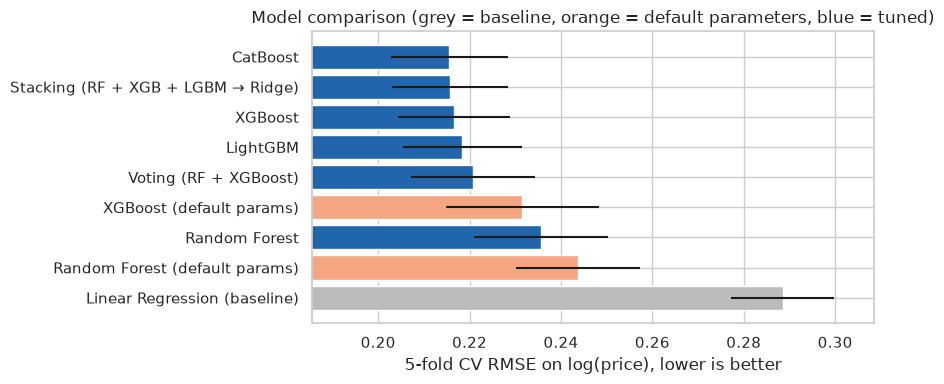

In [11]:
res = pd.DataFrame(results).sort_values("CV RMSE (log)").reset_index(drop=True)
display(res.style.format(precision=3).background_gradient(subset=["CV RMSE (log)"], cmap="Greens_r"))
colors = res["family"].map({"baseline": "#bbbbbb", "default": "#f4a582", "ensemble": "#2166ac"})
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(res["model"], res["CV RMSE (log)"], xerr=res["CV std"], color=colors); ax.invert_yaxis()
ax.set(xlabel="5-fold CV RMSE on log(price), lower is better",
       title="Model comparison (grey = baseline, orange = default parameters, blue = tuned)")
lo = res["CV RMSE (log)"].min()
ax.set_xlim(lo - 0.03, res["CV RMSE (log)"].max() + 0.02); plt.tight_layout(); plt.show()

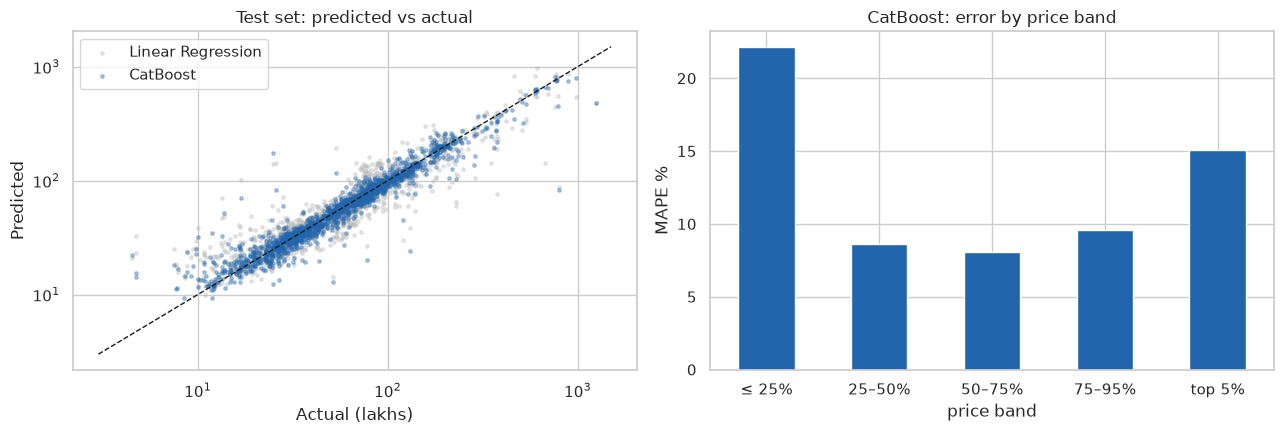

In [12]:
best_name = res.iloc[0]["model"]
best = fitted[best_name]
pred = np.expm1(best.predict(X_test))
base = np.expm1(fitted["Linear Regression (baseline)"].predict(X_test))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, base, s=6, alpha=.35, c="#bbbbbb", label="Linear Regression")
ax[0].scatter(y_test, pred, s=6, alpha=.35, c="#2166ac", label=best_name)
ax[0].plot([3, 1500], [3, 1500], "k--", lw=1); ax[0].set(xscale="log", yscale="log", xlabel="Actual (lakhs)",
            ylabel="Predicted", title="Test set: predicted vs actual"); ax[0].legend()
band = pd.qcut(y_test, [0, .25, .5, .75, .95, 1], labels=["≤ 25%", "25–50%", "50–75%", "75–95%", "top 5%"])
err = pd.DataFrame({"band": band, "err": 100 * np.abs(pred - y_test) / y_test}).groupby("band", observed=True)["err"].mean()
err.plot.bar(ax=ax[1], color="#2166ac"); ax[1].set(ylabel="MAPE %", xlabel="price band", title=f"{best_name}: error by price band")
ax[1].tick_params(axis="x", rotation=0); plt.tight_layout(); plt.show()

## 8. Results and choosing the model
**Interpretation**
* **Every tuned ensemble clearly beats the linear baseline.** CatBoost lowers the CV error by about 25%
  (0.289 → 0.216). Test MAPE falls from 20.1% to 12.4%, and R² rises from 0.78 to 0.88. Linear regression
  cannot learn that depreciation differs by brand and fuel.
* **Tuning matters.** Compared with the default settings, tuning improves Random Forest by about 3%
  (0.244 → 0.236) and XGBoost by about 7% (0.232 → 0.217).
* **The top four are practically tied.** CatBoost (0.2156), stacking (0.2157), XGBoost (0.2165) and LightGBM
  (0.2184) all fall within one CV standard deviation (about 0.013). Boosting beats bagging (Random Forest 0.236) on this data.
* **Voting (Lecture 7 pipeline)** (0.221) beats Random Forest alone but not XGBoost alone, because equal
  weights give the weaker Random Forest half the vote. Stacking learns the weights instead, so it does better.
* **Errors are smallest for mid-priced cars (about 8–10%)** and largest for the cheapest quarter (about 22%: old
  Altos and Marutis, where condition matters more than the specs) and the top 5% (about 15%: few luxury adverts to learn from).

**Why CatBoost is the final model**
1. It has the **lowest cross-validation error**. The model was chosen on CV, not on the test set, so the test set stays a fair check.
2. It **handles text categories natively.** `model` has about 100 values, and CatBoost's built-in encoding avoids
   both one-hot sparsity and target leakage.
3. It is **one model, not four.** Stacking ties it, but needs three models plus a meta-model, which makes the
   app slower and the explanation harder. CatBoost also gives exact SHAP values directly.

| Model | Strengths | Limitations (seen here) |
|---|---|---|
| Linear Regression | simple, transparent | misses interactions; 20% error |
| Random Forest (bagging) | robust, few settings | weakest ensemble here; large model file |
| XGBoost (boosting) | accurate, regularised | many settings to tune; categories must be encoded |
| LightGBM (boosting) | fastest | overfits easily on small data (needs small steps) |
| CatBoost (boosting) | best CV, native categories, exact SHAP | slowest to tune |
| Voting | simple to build | the weaker model drags it down |
| Stacking | learns how to combine models | three times the cost, no gain over CatBoost |

## 9. SHAP: what drives prices overall, and for one car

Average predicted price (SHAP base value): Rs. 56.0 L


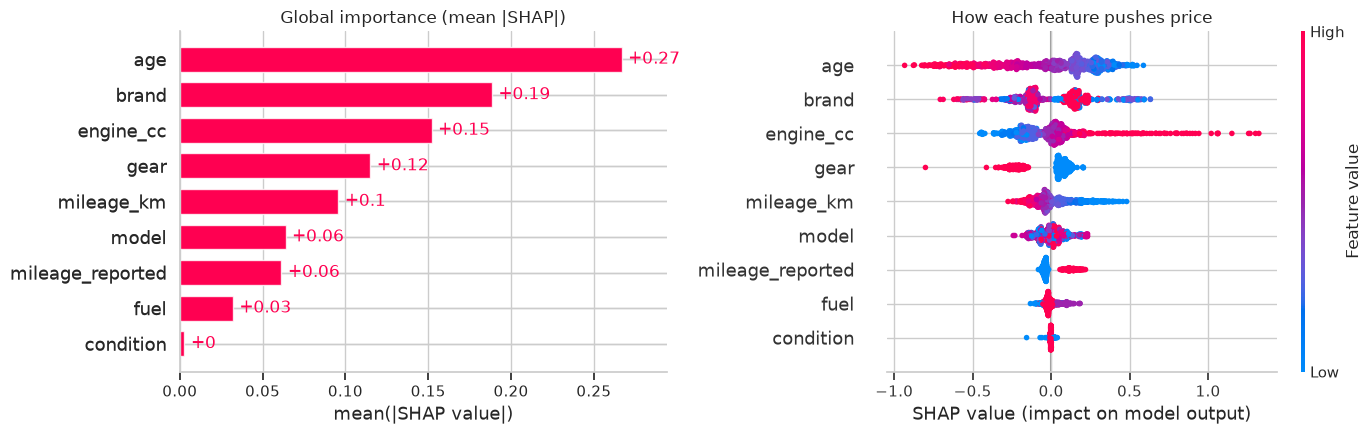

In [13]:
cat = best.named_steps["m"]
from catboost import Pool
sample = X_train.sample(1000, random_state=1)
sv = cat.get_feature_importance(Pool(sample, cat_features=CAT_FEATURES), type="ShapValues")  # exact TreeSHAP
shap_vals, base_value = sv[:, :-1], sv[0, -1]
# for the colour scale, categories are shown as codes
codes = sample.apply(lambda c: c if pd.api.types.is_numeric_dtype(c) else c.astype("category").cat.codes)
expl = shap.Explanation(shap_vals, base_values=np.full(len(sample), base_value), feature_names=FEATURES,
                        data=codes.values)
print(f"Average predicted price (SHAP base value): Rs. {np.expm1(base_value):.1f} L")
fig = plt.figure(figsize=(14, 4.5))
plt.subplot(1, 2, 1); shap.plots.bar(expl, show=False, ax=plt.gca()); plt.title("Global importance (mean |SHAP|)")
plt.subplot(1, 2, 2); shap.plots.beeswarm(expl, show=False, plot_size=None); plt.title("How each feature pushes price")
plt.tight_layout(); plt.show()

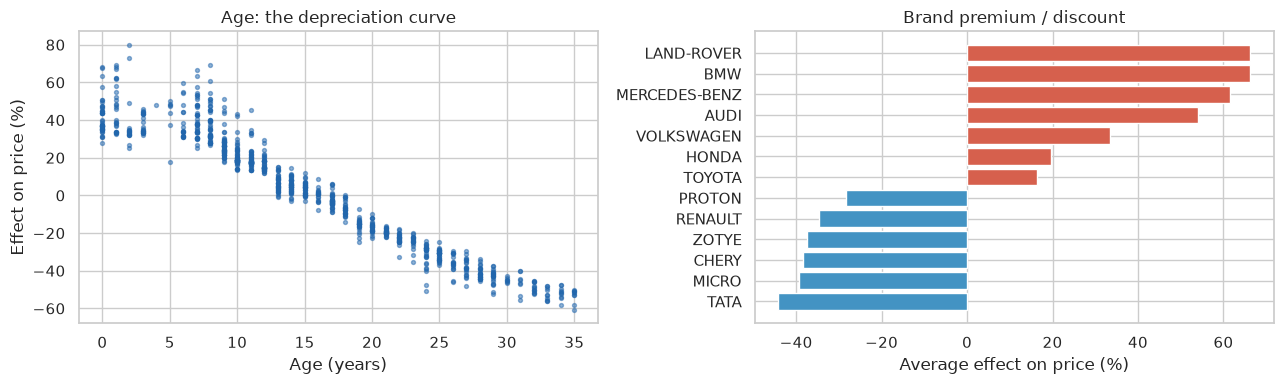

In [14]:
d = pd.DataFrame(shap_vals, columns=FEATURES)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(sample["age"], 100 * (np.exp(d["age"]) - 1), s=8, alpha=.5, c="#2166ac")
ax[0].set(xlabel="Age (years)", ylabel="Effect on price (%)", title="Age: the depreciation curve")
brand = (100 * (np.exp(d.groupby(sample["brand"].values)["brand"].mean()) - 1)).sort_values()
sel = pd.concat([brand.head(6), brand.tail(7)])
ax[1].barh(sel.index, sel.values, color=np.where(sel.values > 0, "#d6604d", "#4393c3"))
ax[1].set(xlabel="Average effect on price (%)", title="Brand premium / discount")
plt.tight_layout(); plt.show()

**What SHAP shows (global)**
* **Age is the biggest driver.** Price falls by roughly 3–4% per year in a near-straight line. Cars up to about
  8 years old keep a premium, because recent cars were scarce while imports were banned.
* **Brand is second.** Land Rover, BMW, Mercedes and Audi carry +55–65%, and Toyota and Honda about +15–20%.
  Tata, Micro, Chery and Zotye carry −35–45%. This matches Sri Lankan resale reputation.
* **Engine size and gearbox come next.** Bigger engines and automatics cost more.
* **Mileage matters less than expected** because most real mileage values were missing (see EDA). Cars whose
  advert *hides* the mileage are priced lower, as if buyers treat it as a warning sign.
* **Fuel and model add little on their own,** because brand + engine + gearbox already identify most cars.

## 10. LIME, and comparing it with SHAP on one car

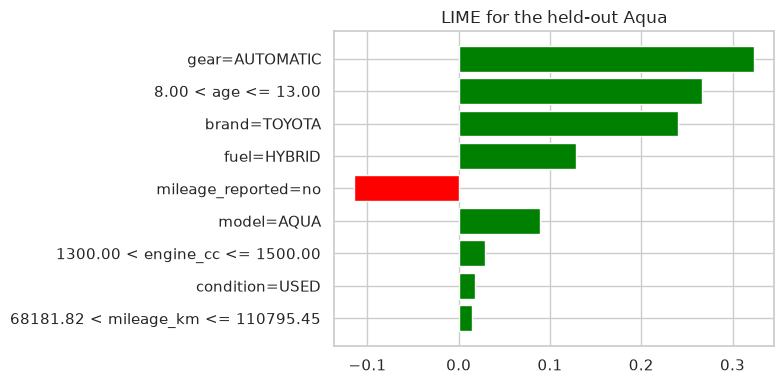

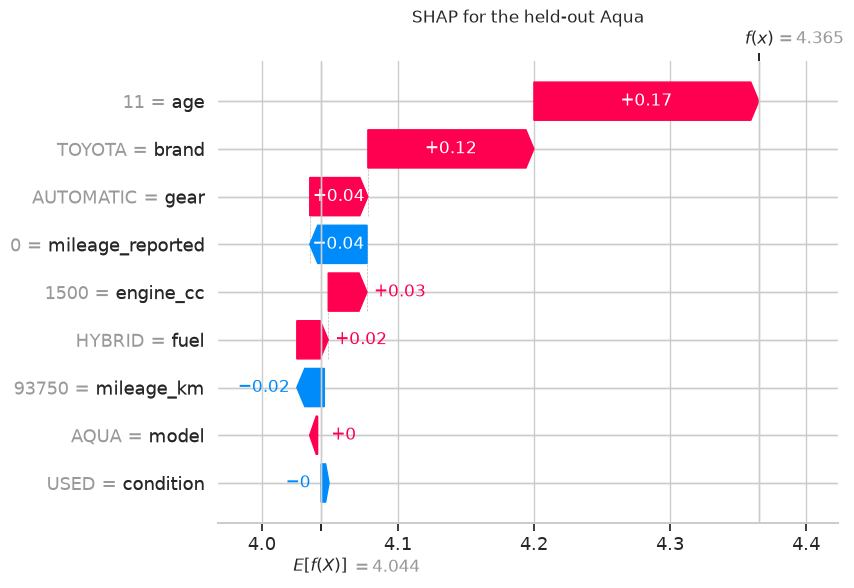

,SHAP effect %,LIME effect %
age,18.0,30.5
brand,13.0,27.1
gear,4.4,38.2
mileage_reported,-4.1,-10.8
engine_cc,2.9,2.9
fuel,2.3,13.7
mileage_km,-2.0,1.5
model,0.5,9.3
condition,-0.3,1.8


LIME local fit R²: 0.21


In [15]:
car = fill_missing(holdout, stats)
# LIME needs numbers: encode categories as integer codes, and decode them again inside the predict function
levels = {c: sorted(set(X_train[c]) | {"OTHER"}) for c in CAT_FEATURES}
def encode(X):
    X = X.copy()
    for c in CAT_FEATURES:
        X[c] = X[c].map({v: i for i, v in enumerate(levels[c])})
    return X.astype(float).values
def predict_from_codes(A):
    X = pd.DataFrame(A, columns=FEATURES)
    for c in CAT_FEATURES:
        X[c] = [levels[c][int(np.clip(round(v), 0, len(levels[c]) - 1))] for v in X[c]]
    X["mileage_reported"] = X["mileage_reported"].round()
    return best.predict(X)
cat_idx = [FEATURES.index(c) for c in CAT_FEATURES] + [FEATURES.index("mileage_reported")]
lime = LimeTabularExplainer(encode(X_train.sample(500, random_state=0)), mode="regression", feature_names=FEATURES,
                            categorical_features=cat_idx, random_state=SEED,
                            categorical_names={**{FEATURES.index(c): levels[c] for c in CAT_FEATURES},
                                               FEATURES.index("mileage_reported"): ["no", "yes"]})
exp = lime.explain_instance(encode(car)[0], predict_from_codes, num_features=9, num_samples=5000)
fig = exp.as_pyplot_figure(); fig.set_size_inches(8, 4); plt.title("LIME for the held-out Aqua"); plt.tight_layout(); plt.show()

one = cat.get_feature_importance(Pool(car, cat_features=CAT_FEATURES), type="ShapValues")[0]
shap.plots.waterfall(shap.Explanation(values=one[:-1], base_values=one[-1], data=car.iloc[0].values,
                                     feature_names=FEATURES), show=False)
plt.title("SHAP for the held-out Aqua"); plt.show()
compare = pd.DataFrame({"SHAP effect %": 100 * (np.exp(one[:-1]) - 1)}, index=FEATURES).round(1)
# match each LIME rule to its feature (longest name first: "age" is also inside "mileage")
lime_eff = {max([f for f in FEATURES if f in rule], key=len): round(100 * (np.exp(w) - 1), 1)
            for rule, w in exp.as_list()}
compare["LIME effect %"] = pd.Series(lime_eff)
display(compare.sort_values("SHAP effect %", key=abs, ascending=False))
print(f"LIME local fit R²: {exp.score:.2f}")

**SHAP vs LIME for this car**
* **They agree on the direction of the main drivers:** Toyota, automatic, hybrid and a mid-age car push the price up, and a hidden mileage pushes it down.
* **They disagree on the size.** LIME gives much larger effects (for example, automatic is about +38% in LIME
  vs +4% in SHAP), and its local linear fit is weak (R² about 0.2).
* **Why:** SHAP splits *this* prediction exactly, and its values add up to the predicted price. LIME changes one
  feature at a time at random (creating unrealistic cars such as a manual hybrid Aqua) and fits a straight line around them.
* **Conclusion:** SHAP is used in the app because it is exact and consistent. LIME is a useful, human-readable
  cross-check ("age between 9 and 14 years", "brand = Toyota").

## 11. Inference on a new car, and saving the model with pickle

In [16]:
bundle = {"model": cat, "fill_stats": stats, "features": FEATURES, "model_name": best_name,
          "test_mape": float(res.iloc[0]["Test MAPE %"]), "test_r2": float(res.iloc[0]["Test R²"]),
          "brand_models": train.groupby("brand")["model"].apply(lambda s: sorted(s.unique())).to_dict()}
pickle.dump(bundle, open("model.pkl", "wb"))

# Reload it exactly as the app does, and predict the car the model has never seen
loaded = pickle.load(open("model.pkl", "rb"))
x = fill_missing(holdout, loaded["fill_stats"])
p = float(np.expm1(loaded["model"].predict(x))[0])
display(holdout[["brand", "model_full", "YOM", "engine_cc", "gear", "fuel", "condition", "price"]])
print(f"Actual price: Rs. {holdout['price'].iloc[0]:.1f} L   Predicted: Rs. {p:.1f} L   "
      f"(error {100 * (p / holdout['price'].iloc[0] - 1):+.1f}%)")

,brand,model_full,YOM,engine_cc,gear,fuel,condition,price
6487,TOYOTA,AQUA,2014,1500.0,AUTOMATIC,HYBRID,USED,79.5


Actual price: Rs. 79.5 L   Predicted: Rs. 77.7 L   (error -2.3%)


In [17]:
# Sanity check (does the model behave sensibly?): the same Aqua at different ages
from car_utils import make_input_row
ages = [2, 5, 8, 12, 16, 20]
prices = [float(np.expm1(loaded["model"].predict(fill_missing(make_input_row(
    "TOYOTA", "AQUA", 2026 - a, 1500, "AUTOMATIC", "HYBRID", "USED", 10000 * a), stats)))[0]) for a in ages]
print("Age  -> price:", {a: round(p_, 1) for a, p_ in zip(ages, prices)})

Age  -> price: {2: 146.4, 5: 134.0, 8: 111.4, 12: 81.2, 16: 71.2, 20: 55.2}


## 12. The application
`app.py` is a small Streamlit app built with GenAI help. It loads
`model.pkl`, takes the car details from a form, fills any missing values the same way as above, and shows
the predicted price with a SHAP chart explaining it.
```
pip install -r requirements.txt
streamlit run app.py
```

## 13. Conclusion
* A tuned **CatBoost** model predicts Sri Lankan used-car asking prices with **R² 0.88 and about 12% average error**
  on cars it has never seen. That is about 25% lower error than linear regression.
* **SHAP** shows it learned sensible market logic: steady depreciation, brand reputation, engine size and an
  automatic premium. **LIME** confirms the direction of these effects.
* The held-out 2014 Toyota Aqua was predicted at **Rs. 77.7 L against an actual Rs. 79.5 L (−2.3%)**.

**Limitations**
* The model learns *asking* prices, not final sale prices.
* Mileage in the source is mostly filled in. Accident history, number of owners, registration status and
  location are not in the data.
* **The market shifted after imports reopened in 2025:** 2026 listings are much newer cars. `drift_check.py`
  detects this, and the model should be retrained regularly (the MLOps part).